# 02 - Modélisation : comparaison des baselines

Entraînement de modèles de régression avec leurs paramètres par défaut, évaluation sur un jeu de test séparé et suivi de chaque essai dans MLflow.

Cible : `Yield_tons_per_hectare` (t/ha). Données d'entraînement : `crop_yield` nettoyé (notebook 01).

## 1. Imports et configuration

In [1]:
import gc
import platform
import socket
import subprocess
import sys
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from mlflow.models import infer_signature
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

sns.set_theme(style="whitegrid")

SEED = 42
np.random.seed(SEED)

DATA_RAW = Path("../data/raw")
DATA_PROCESSED = Path("../data/processed")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

TARGET = "Yield_tons_per_hectare"

# Taille de l'échantillon d'entraînement commun à tous les modèles (None : jeu d'entraînement complet)
N_TRAIN_SAMPLE = 100_000

print(f"python {platform.python_version()} | mlflow {mlflow.__version__} | scikit-learn {sklearn.__version__} | pandas {pd.__version__} | xgboost : {HAS_XGB}")

python 3.11.9 | mlflow 3.17.2 | scikit-learn 1.9.1 | pandas 3.1.0 | xgboost : True


## 2. MLflow

Configuration du suivi (base SQLite locale `mlflow.db`, artefacts dans `mlruns/`), création de l'expérience `crop-yield-baselines` et lancement du serveur de l'interface sur le port 5000 s'il n'est pas déjà actif.

In [2]:
PROJECT_ROOT = Path("..").resolve()
DB_PATH = PROJECT_ROOT / "mlflow.db"
ARTIFACT_ROOT = PROJECT_ROOT / "mlruns"
TRACKING_URI = f"sqlite:///{DB_PATH.as_posix()}"
MLFLOW_PORT = 5000
MLFLOW_URL = f"http://127.0.0.1:{MLFLOW_PORT}"
EXPERIMENT_NAME = "crop-yield-baselines"

mlflow.set_tracking_uri(TRACKING_URI)
if mlflow.get_experiment_by_name(EXPERIMENT_NAME) is None:
    mlflow.create_experiment(EXPERIMENT_NAME, artifact_location=ARTIFACT_ROOT.as_uri())
mlflow.set_experiment(EXPERIMENT_NAME)


def port_open(port, host="127.0.0.1"):
    with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
        s.settimeout(0.5)
        return s.connect_ex((host, port)) == 0


if port_open(MLFLOW_PORT):
    print(f"Serveur MLflow déjà actif sur {MLFLOW_URL}")
else:
    # Équivalent en terminal : mlflow ui --backend-store-uri <TRACKING_URI> --port 5000
    log_file = open(PROJECT_ROOT / "mlflow_ui.log", "w")
    mlflow_proc = subprocess.Popen(
        [sys.executable, "-m", "mlflow", "ui",
         "--backend-store-uri", TRACKING_URI,
         "--port", str(MLFLOW_PORT), "--host", "127.0.0.1"],
        stdout=log_file, stderr=subprocess.STDOUT,
    )
    for _ in range(40):
        if port_open(MLFLOW_PORT):
            break
        time.sleep(0.5)
    print("Serveur MLflow lancé" if port_open(MLFLOW_PORT) else "Échec du lancement (voir mlflow_ui.log)")

try:
    status = urllib.request.urlopen(MLFLOW_URL, timeout=5).status
    print(f"Interface MLflow accessible : {MLFLOW_URL} (HTTP {status})")
except Exception as e:
    print("Interface MLflow non joignable :", e)
print("Expérience active :", EXPERIMENT_NAME)

Serveur MLflow déjà actif sur http://127.0.0.1:5000
Interface MLflow accessible : http://127.0.0.1:5000 (HTTP 200)
Expérience active : crop-yield-baselines


## 3. Chargement des données

In [3]:
clean_path = DATA_PROCESSED / "crop_yield_clean.csv"
if clean_path.exists():
    df = pd.read_csv(clean_path)
else:
    df = pd.read_csv(DATA_RAW / "crop_yield.csv").drop_duplicates()
    df = df[df[TARGET] >= 0].reset_index(drop=True)
    df.to_csv(clean_path, index=False)
    print("CSV nettoyé reconstruit et enregistré.")

print("Forme :", df.shape, "| manquants :", int(df.isna().sum().sum()), "| rendements négatifs :", int((df[TARGET] < 0).sum()))
df.head(3)

Forme : (999769, 10) | manquants : 0 | rendements négatifs : 0


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,West,Sandy,Cotton,897.077239,27.676966,False,True,Cloudy,122,6.555816
1,South,Clay,Rice,992.673282,18.026142,True,True,Rainy,140,8.527341
2,North,Loam,Barley,147.998025,29.794042,False,False,Sunny,106,1.127443


## 4. Découpage train / test

Séparation 80 / 20 avec seed fixé. Les variables sont réparties en numériques, binaires (converties en 0/1) et catégorielles. Un échantillon de `N_TRAIN_SAMPLE` lignes du jeu d'entraînement est utilisé pour tous les modèles.

In [4]:
num_cols = ["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest"]
bool_cols = ["Fertilizer_Used", "Irrigation_Used"]
cat_cols = ["Region", "Soil_Type", "Crop", "Weather_Condition"]
FEATURES = num_cols + bool_cols + cat_cols

X = df[FEATURES].copy()
X[bool_cols] = X[bool_cols].astype(int)
y = df[TARGET]

X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"Train complet : {len(X_train_full):,} lignes | Test : {len(X_test):,} lignes")

if N_TRAIN_SAMPLE is not None and N_TRAIN_SAMPLE < len(X_train_full):
    X_train = X_train_full.sample(N_TRAIN_SAMPLE, random_state=SEED)
    y_train = y_train_full.loc[X_train.index]
else:
    X_train, y_train = X_train_full, y_train_full
print(f"Échantillon d'entraînement : {len(X_train):,} lignes")

del X_train_full, y_train_full, X
gc.collect()

print("Rendement moyen train / test :", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))
print("Écart-type du rendement train / test :", round(y_train.std(), 3), "/", round(y_test.std(), 3))

Train complet : 799,815 lignes | Test : 199,954 lignes
Échantillon d'entraînement : 100,000 lignes
Rendement moyen train / test : 4.655 / 4.652
Écart-type du rendement train / test : 1.691 / 1.695


## 5. Prétraitement

Pipeline commun à tous les modèles, ajusté sur le jeu d'entraînement uniquement :
- variables numériques : standardisation ;
- variables binaires : conservées en 0/1 ;
- variables catégorielles : encodage one-hot, valeurs inconnues ignorées.

In [5]:
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_cols),
            ("bool", "passthrough", bool_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ],
        remainder="drop",
    )

make_preprocessor()

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bool', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_

## 6. Baselines

Modèles entraînés avec leurs hyperparamètres par défaut (seul `random_state` est fixé) :

| Modèle | Type |
|---|---|
| DummyRegressor | Référence (prédiction de la moyenne) |
| LinearRegression | Linéaire |
| Ridge | Linéaire régularisé |
| RandomForestRegressor | Non linéaire, bagging |
| HistGradientBoostingRegressor | Non linéaire, boosting |
| XGBRegressor | Non linéaire, boosting (si installé) |

In [6]:
BASELINES = {
    "baseline-dummy-mean": DummyRegressor(strategy="mean"),
    "baseline-linear": LinearRegression(),
    "baseline-ridge": Ridge(random_state=SEED),
    "baseline-random-forest": RandomForestRegressor(random_state=SEED, n_jobs=-1),
    "baseline-hist-gradient-boosting": HistGradientBoostingRegressor(random_state=SEED),
}
if HAS_XGB:
    BASELINES["baseline-xgboost"] = XGBRegressor(random_state=SEED, n_jobs=-1)

DESCRIPTIONS = {
    "baseline-dummy-mean": "Référence : prédit la moyenne du rendement d'entraînement.",
    "baseline-linear": "Régression linéaire, paramètres par défaut.",
    "baseline-ridge": "Ridge (alpha=1), paramètres par défaut.",
    "baseline-random-forest": "Random Forest, 100 arbres, profondeur non limitée.",
    "baseline-hist-gradient-boosting": "Gradient boosting par histogrammes, paramètres par défaut.",
    "baseline-xgboost": "XGBoost, paramètres par défaut.",
}
list(BASELINES)

['baseline-dummy-mean',
 'baseline-linear',
 'baseline-ridge',
 'baseline-random-forest',
 'baseline-hist-gradient-boosting',
 'baseline-xgboost']

## 7. Entraînement et suivi MLflow

Un run MLflow par modèle, avec :
- paramètres : modèle, hyperparamètres, seed, tailles des jeux, variables ;
- métriques : RMSE, MAE et R² sur le train et sur le test, écarts train / test, temps d'entraînement ;
- artefact : pipeline complet (prétraitement et modèle) avec signature ;
- tags : étape, famille de modèle, description.

In [8]:
def evaluate(pipe, Xa, ya):
    pred = pipe.predict(Xa)
    return {
        "rmse": float(np.sqrt(mean_squared_error(ya, pred))),
        "mae": float(mean_absolute_error(ya, pred)),
        "r2": float(r2_score(ya, pred)),
    }


def log_pipeline(pipe, X_example, name="model"):
    signature = infer_signature(X_example, pipe.predict(X_example))
    kwargs = dict(
        signature=signature,
        input_example=X_example.head(3),
        serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_CLOUDPICKLE,
    )
    try:
        return mlflow.sklearn.log_model(pipe, name=name, **kwargs)
    except TypeError:
        return mlflow.sklearn.log_model(pipe, artifact_path=name, **kwargs)

def get_clean_params(model):
    params = model.get_params()
    return {f"model__{k}": (str(v) if v is None or not isinstance(v, (int, float, str, bool)) else v)
            for k, v in params.items()}


results = []
for run_name, model in BASELINES.items():
    pipe = Pipeline([("preprocess", make_preprocessor()), ("model", model)])

    with mlflow.start_run(run_name=run_name) as run:
        mlflow.set_tags({
            "stage": "baseline",
            "model_family": type(model).__name__,
            "mlflow.note.content": DESCRIPTIONS[run_name],
            "target": TARGET,
        })
        mlflow.log_params({
            "seed": SEED,
            "n_train": len(X_train),
            "n_test": len(X_test),
            "n_features_raw": len(FEATURES),
            "features": ",".join(FEATURES),
            "test_size": 0.2,
            **get_clean_params(model),
        })

        t0 = time.perf_counter()
        pipe.fit(X_train, y_train)
        fit_time = time.perf_counter() - t0

        m_train = evaluate(pipe, X_train, y_train)
        m_test = evaluate(pipe, X_test, y_test)

        mlflow.log_metrics({
            "train_rmse": m_train["rmse"], "train_mae": m_train["mae"], "train_r2": m_train["r2"],
            "test_rmse": m_test["rmse"], "test_mae": m_test["mae"], "test_r2": m_test["r2"],
            "gap_rmse_test_minus_train": m_test["rmse"] - m_train["rmse"],
            "gap_r2_train_minus_test": m_train["r2"] - m_test["r2"],
            "fit_time_s": fit_time,
        })
        log_pipeline(pipe, X_train)

        results.append({"run_name": run_name, "run_id": run.info.run_id, "fit_time_s": fit_time,
                        **{f"train_{k}": v for k, v in m_train.items()},
                        **{f"test_{k}": v for k, v in m_test.items()}})
    del pipe
    gc.collect()
    print(f"{run_name:34s} test RMSE = {m_test['rmse']:.4f} | test R2 = {m_test['r2']:.4f} | {fit_time:6.1f} s")

res = pd.DataFrame(results)

c:\Users\ethan\Documents\OpenClassrooms\agritech-answers\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/06 11:06:06 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, w

baseline-dummy-mean                test RMSE = 1.6950 | test R2 = -0.0000 |    0.2 s


c:\Users\ethan\Documents\OpenClassrooms\agritech-answers\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/06 11:06:14 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, w

baseline-linear                    test RMSE = 0.4993 | test R2 = 0.9132 |    0.3 s


c:\Users\ethan\Documents\OpenClassrooms\agritech-answers\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/06 11:06:21 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, w

baseline-ridge                     test RMSE = 0.4993 | test R2 = 0.9132 |    0.2 s


... (2 outputs left out)

c:\Users\ethan\Documents\OpenClassrooms\agritech-answers\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/06 11:06:49 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, w

baseline-hist-gradient-boosting    test RMSE = 0.5009 | test R2 = 0.9127 |    0.6 s


c:\Users\ethan\Documents\OpenClassrooms\agritech-answers\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/06 11:06:56 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, w

baseline-xgboost                   test RMSE = 0.5071 | test R2 = 0.9105 |    0.6 s


## 8. Comparaison des modèles

In [9]:
summary = (res.assign(gap_r2=lambda d: d["train_r2"] - d["test_r2"])
              .sort_values("test_rmse")
              [["run_name", "test_rmse", "test_mae", "test_r2", "train_rmse", "train_r2", "gap_r2", "fit_time_s"]]
              .reset_index(drop=True))
summary.round(4)

,run_name,test_rmse,test_mae,test_r2,train_rmse,train_r2,gap_r2,fit_time_s
0,baseline-ridge,0.4993,0.3983,0.9132,0.4988,0.9130,-0.0002,0.2166
1,baseline-linear,0.4993,0.3983,0.9132,0.4988,0.9130,-0.0002,0.2700
2,baseline-hist-gradient-boosting,0.5009,0.3997,0.9127,0.4943,0.9146,0.0020,0.6005
3,baseline-xgboost,0.5071,0.4046,0.9105,0.4713,0.9224,0.0118,0.6423
4,baseline-random-forest,0.5185,0.4136,0.9064,0.1934,0.9869,0.0805,7.5121
5,baseline-dummy-mean,1.6950,1.3882,-0.0000,1.6914,0.0000,0.0000,0.1897


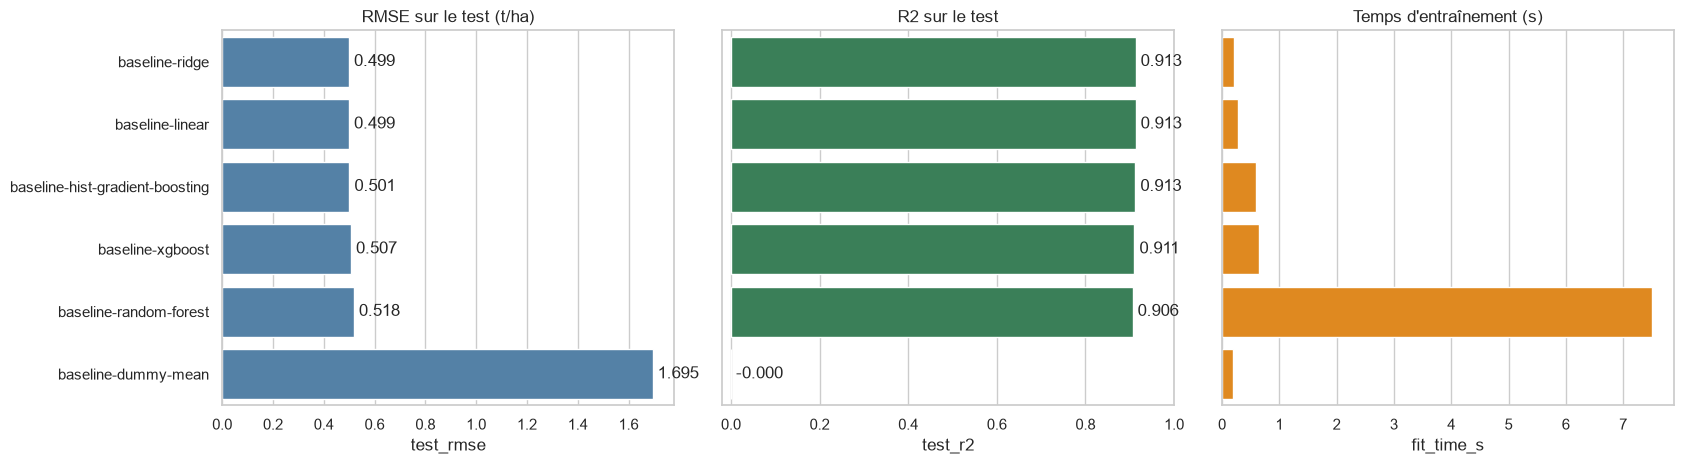

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
order = summary["run_name"]

sns.barplot(data=summary, y="run_name", x="test_rmse", order=order, ax=axes[0], color="steelblue")
axes[0].set_title("RMSE sur le test (t/ha)"); axes[0].set_ylabel("")
for p in axes[0].patches:
    axes[0].text(p.get_width(), p.get_y() + p.get_height() / 2, f" {p.get_width():.3f}", va="center")

sns.barplot(data=summary, y="run_name", x="test_r2", order=order, ax=axes[1], color="seagreen")
axes[1].set_title("R2 sur le test"); axes[1].set_ylabel(""); axes[1].set_yticklabels([])
axes[1].set_xlim(min(0, summary["test_r2"].min()) - 0.02, 1)
for p in axes[1].patches:
    axes[1].text(p.get_width(), p.get_y() + p.get_height() / 2, f" {p.get_width():.3f}", va="center")

sns.barplot(data=summary, y="run_name", x="fit_time_s", order=order, ax=axes[2], color="darkorange")
axes[2].set_title("Temps d'entraînement (s)"); axes[2].set_ylabel(""); axes[2].set_yticklabels([])
plt.tight_layout(); plt.savefig(FIG_DIR / "20_comparaison_baselines.png", dpi=120); plt.show()

In [11]:
runs = mlflow.search_runs(experiment_names=[EXPERIMENT_NAME], order_by=["metrics.test_rmse ASC"])
cols = ["tags.mlflow.runName", "metrics.test_rmse", "metrics.test_mae", "metrics.test_r2",
        "metrics.gap_r2_train_minus_test", "metrics.fit_time_s", "status"]
print(f"{len(runs)} run(s) enregistré(s) dans l'expérience '{EXPERIMENT_NAME}' ({MLFLOW_URL})")
runs[cols].round(4)

10 run(s) enregistré(s) dans l'expérience 'crop-yield-baselines' (http://127.0.0.1:5000)


,tags.mlflow.runName,metrics.test_rmse,metrics.test_mae,metrics.test_r2,metrics.gap_r2_train_minus_test,metrics.fit_time_s,status
0,baseline-ridge,0.4993,0.3983,0.9132,-0.0002,0.2166,FINISHED
1,baseline-ridge,0.4993,0.3983,0.9132,-0.0002,0.1792,FINISHED
2,baseline-linear,0.4993,0.3983,0.9132,-0.0002,0.2700,FINISHED
3,baseline-linear,0.4993,0.3983,0.9132,-0.0002,0.2962,FINISHED
4,baseline-hist-gradient-boosting,0.5009,0.3997,0.9127,0.0020,0.6005,FINISHED
5,baseline-xgboost,0.5071,0.4046,0.9105,0.0118,0.6423,FINISHED
6,baseline-random-forest,0.5185,0.4136,0.9064,0.0805,6.9584,FAILED
7,baseline-random-forest,0.5185,0.4136,0.9064,0.0805,7.5121,FINISHED
8,baseline-dummy-mean,1.6950,1.3882,-0.0000,0.0000,0.1897,FINISHED
9,baseline-dummy-mean,1.6950,1.3882,-0.0000,0.0000,0.3496,FINISHED


## 9. Diagnostic du meilleur modèle

Rechargement du pipeline depuis MLflow, comparaison réel / prédit et analyse des résidus sur le jeu de test.

Meilleur modèle sur le test : baseline-ridge
RMSE test : 0.4993 | biais moyen des résidus : +0.0013


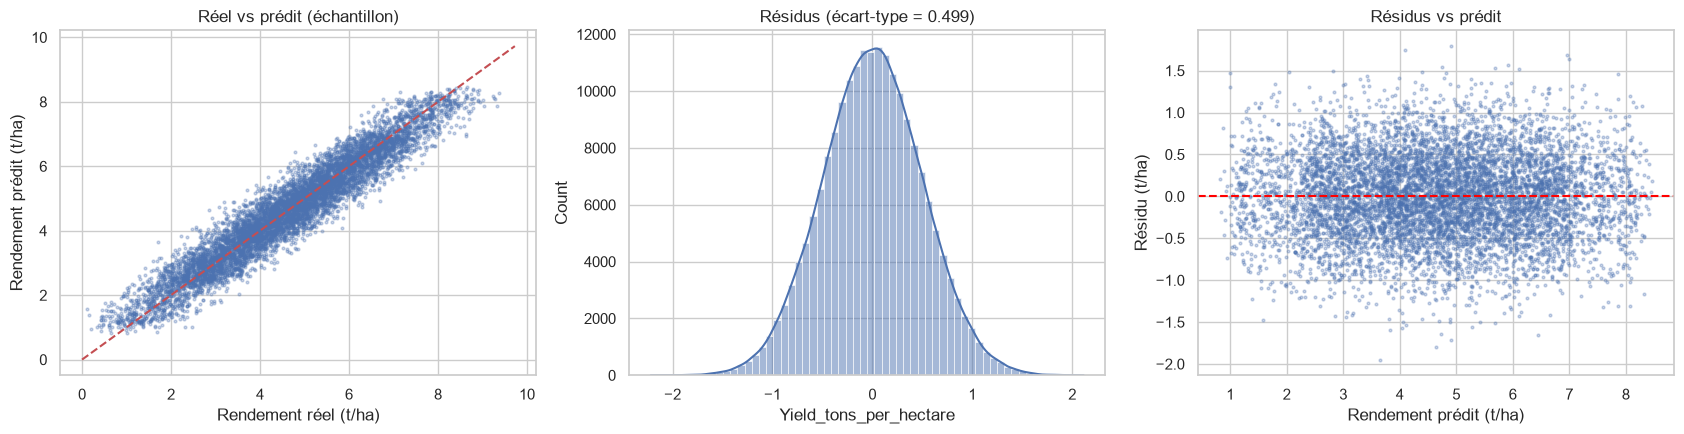

In [12]:
best_name = summary.loc[0, "run_name"]
best_id = res.set_index("run_name").loc[best_name, "run_id"]
best_model = mlflow.sklearn.load_model(f"runs:/{best_id}/model")
print("Meilleur modèle sur le test :", best_name)

pred = best_model.predict(X_test)
resid = y_test - pred
print(f"RMSE test : {np.sqrt(np.mean(resid**2)):.4f} | biais moyen des résidus : {resid.mean():+.4f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
idx = np.random.default_rng(SEED).choice(len(y_test), 8000, replace=False)
ax[0].scatter(y_test.iloc[idx], pred[idx], s=4, alpha=.3)
lim = [0, max(y_test.max(), pred.max())]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Rendement réel (t/ha)"); ax[0].set_ylabel("Rendement prédit (t/ha)")
ax[0].set_title("Réel vs prédit (échantillon)")
sns.histplot(resid, bins=60, kde=True, ax=ax[1]); ax[1].set_title(f"Résidus (écart-type = {resid.std():.3f})")
ax[2].scatter(pred[idx], resid.iloc[idx], s=4, alpha=.3); ax[2].axhline(0, color="red", ls="--")
ax[2].set_xlabel("Rendement prédit (t/ha)"); ax[2].set_ylabel("Résidu (t/ha)"); ax[2].set_title("Résidus vs prédit")
plt.tight_layout(); plt.savefig(FIG_DIR / "21_diagnostic_meilleur_baseline.png", dpi=120); plt.show()

## 10. Effet de la culture sur les prédictions

Pour 2 000 contextes du jeu de test, le rendement est prédit avec le meilleur modèle pour chacune des cultures (le contexte restant identique). L'écart entre cultures est comparé au RMSE du modèle.

In [13]:
crops = sorted(df["Crop"].unique())
ctx = X_test.sample(2000, random_state=SEED).reset_index(drop=True)

pred_by_crop = pd.DataFrame({c: best_model.predict(ctx.assign(Crop=c)) for c in crops})
spread = pred_by_crop.max(axis=1) - pred_by_crop.min(axis=1)

print("Écart (max - min) entre cultures pour un même contexte (t/ha) :")
print(spread.describe().round(4))
print("\nRendement prédit moyen par culture (t/ha) :")
print(pred_by_crop.mean().round(4))
print(f"\nRMSE du modèle : {np.sqrt(np.mean(resid**2)):.3f} t/ha")
print("\nCulture classée première (part des contextes) :")
print(pred_by_crop.idxmax(axis=1).value_counts(normalize=True).round(3))

Écart (max - min) entre cultures pour un même contexte (t/ha) :
count    2000.0000
mean        0.0062
std         0.0000
min         0.0062
25%         0.0062
50%         0.0062
75%         0.0062
max         0.0062
dtype: float64

Rendement prédit moyen par culture (t/ha) :
Barley     4.7024
Cotton     4.6987
Maize      4.6980
Rice       4.7035
Soybean    4.7042
Wheat      4.7022
dtype: float64

RMSE du modèle : 0.499 t/ha

Culture classée première (part des contextes) :
Soybean    1.0
Name: proportion, dtype: float64


## 11. Synthèse

In [14]:
non_dummy = summary[summary["run_name"] != "baseline-dummy-mean"]
dummy = summary[summary["run_name"] == "baseline-dummy-mean"].iloc[0]
best = summary.iloc[0]
print(f"Meilleure baseline : {best['run_name']} | RMSE test = {best['test_rmse']:.4f} t/ha | R2 test = {best['test_r2']:.4f}")
print(f"Référence (moyenne) : RMSE test = {dummy['test_rmse']:.4f} t/ha | R2 test = {dummy['test_r2']:.4f}")
print(f"Réduction du RMSE par rapport à la référence : {(1 - best['test_rmse'] / dummy['test_rmse']):.1%}")
print(f"Écart de RMSE entre le meilleur et le moins bon modèle (hors référence) : "
      f"{non_dummy['test_rmse'].max() - non_dummy['test_rmse'].min():.4f} t/ha")
print(f"Runs enregistrés dans MLflow : {len(runs)} | expérience : {EXPERIMENT_NAME}")

Meilleure baseline : baseline-ridge | RMSE test = 0.4993 t/ha | R2 test = 0.9132
Référence (moyenne) : RMSE test = 1.6950 t/ha | R2 test = -0.0000
Réduction du RMSE par rapport à la référence : 70.5%
Écart de RMSE entre le meilleur et le moins bon modèle (hors référence) : 0.0192 t/ha
Runs enregistrés dans MLflow : 10 | expérience : crop-yield-baselines


In [ ]:
## 12. Comparatif incrémental des features (sensibilité à la complexité)
feature_sets = {
    "1_moyenne_seule": [],
    "2_culture_seule": ["Crop"],
    "3_climat_intrants": ["Rainfall_mm", "Temperature_Celsius", "Fertilizer_Used", "Irrigation_Used"],
    "4_toutes_colonnes": FEATURES,
}

incremental_results = []

for name, selected_cols in feature_sets.items():
    if not selected_cols:
        val_rmse = np.sqrt(mean_squared_error(y_test, [y_train.mean()] * len(y_test)))
    else:
        n_c = [c for c in num_cols if c in selected_cols]
        b_c = [c for c in bool_cols if c in selected_cols]
        c_c = [c for c in cat_cols if c in selected_cols]

        transformers = []
        if n_c:
            transformers.append(("num", StandardScaler(), n_c))
        if b_c:
            transformers.append(("bool", "passthrough", b_c))
        if c_c:
            transformers.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), c_c))

        preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")
        pipe = Pipeline([("preprocess", preprocessor), ("model", Ridge(alpha=1.0, random_state=SEED))])

        pipe.fit(X_train[selected_cols], y_train)
        pred = pipe.predict(X_test[selected_cols])
        val_rmse = np.sqrt(mean_squared_error(y_test, pred))

    incremental_results.append({"niveau": name, "test_rmse": round(val_rmse, 4)})

df_incremental = pd.DataFrame(incremental_results)
display(df_incremental)

In [ ]:
## 13. Effets réels des variables clés en t/ha (explicabilité sans standardisation)
features_cles = ["Rainfall_mm", "Temperature_Celsius", "Fertilizer_Used", "Irrigation_Used"]

reg_brute = LinearRegression()
reg_brute.fit(X_train[features_cles], y_train)

df_effets = pd.DataFrame({
    "Variable": features_cles,
    "Effet_t_ha": reg_brute.coef_.round(4),
})

print(f"Intercept : {reg_brute.intercept_:.4f} t/ha")
display(df_effets)